#import library

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Dropout

#upload data

In [4]:
from google.colab import files
uploaded=files.upload()

Saving train.csv to train.csv


In [6]:
df=pd.read_csv('train.csv')
df

,VWTI,SWTI,CWTI,EI,Class
0,2.263400,-4.4862,3.65580,-0.612510,0
1,3.271800,1.7837,2.11610,0.613340,0
2,-3.941100,-12.8792,13.05970,-3.312500,1
3,0.519500,-3.2633,3.08950,-0.984900,0
4,2.569800,-4.4076,5.98560,0.078002,0
...,...,...,...,...,...
1091,1.640600,3.5488,1.39640,-0.364240,0
1092,-0.048008,-1.6037,8.47560,0.755580,0
1093,2.942100,7.4101,-0.97709,-0.884060,0
1094,1.964700,6.9383,0.57722,0.663770,0


In [7]:
df.columns

Index(['VWTI', 'SWTI', 'CWTI', 'EI', 'Class'], dtype='object')

In [8]:
df.shape

(1096, 5)

In [9]:
df.isnull().sum()

,0
VWTI,0
SWTI,0
CWTI,0
EI,0
Class,0


#seperate feature and target

In [16]:
x=df.drop("Class",axis=1)
y=df["Class"]
print("features")
print(x.head())
print("/ntraget:")
print(y.head())

features
     VWTI     SWTI     CWTI        EI
0  2.2634  -4.4862   3.6558 -0.612510
1  3.2718   1.7837   2.1161  0.613340
2 -3.9411 -12.8792  13.0597 -3.312500
3  0.5195  -3.2633   3.0895 -0.984900
4  2.5698  -4.4076   5.9856  0.078002
/ntraget:
0    0
1    0
2    1
3    0
4    0
Name: Class, dtype: int64


#train_test split

In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (876, 4)
Testing data: (220, 4)


#feature scaling

In [21]:
scaler=StandardScaler()
X_train=scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)

#build keras ann model

In [22]:
model = Sequential([
    Dense(32, activation="relu", input_shape=(4,)),
    Dense(16, activation="relu"),
    Dropout(0.2),
    Dense(8, activation="relu"),
    Dense(1, activation="sigmoid")
])

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 833 (3.25 KB)

 Trainable params: 833 (3.25 KB)

 Non-trainable params: 0 (0.00 B)

#compile the model

In [23]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

#train the model

In [24]:
history = model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.20,
    verbose=1
)

Epoch 1/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 3s 25ms/step - accuracy: 0.5871 - loss: 0.6812 - val_accuracy: 0.7159 - val_loss: 0.6553
Epoch 2/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7357 - loss: 0.6302 - val_accuracy: 0.7045 - val_loss: 0.6122
Epoch 3/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7629 - loss: 0.5717 - val_accuracy: 0.7330 - val_loss: 0.5503
Epoch 4/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8243 - loss: 0.4906 - val_accuracy: 0.7557 - val_loss: 0.4737
Epoch 5/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8543 - loss: 0.4047 - val_accuracy: 0.8182 - val_loss: 0.3972
Epoch 6/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8814 - loss: 0.3375 - val_accuracy: 0.8636 - val_loss: 0.3178
Epoch 7/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9200 - loss: 0.2656 - val_accuracy: 0.8920 - val_loss: 0.2411
Epoch 8/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9400 - loss: 0.2014 - val_accuracy: 0.9432 -

#evaluate the model

In [25]:
loss, accuracy = model.evaluate(X_test, y_test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 1.0000 - loss: 2.1918e-04
Test Loss: 0.00021917856065556407
Test Accuracy: 1.0


#accuracy and loss graph

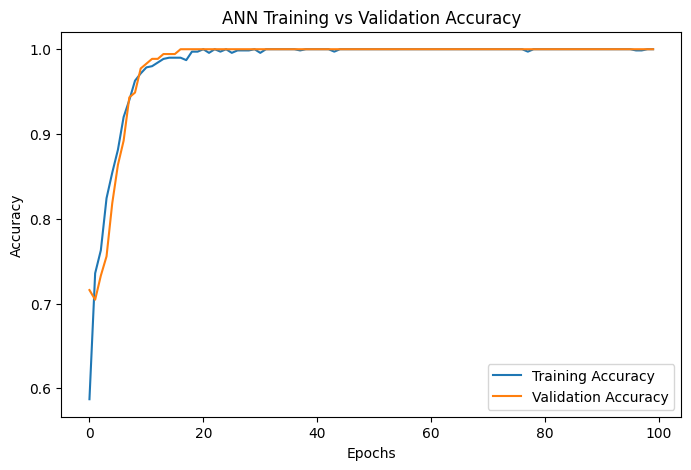

In [26]:
plt.figure(figsize=(8,5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("ANN Training vs Validation Accuracy")
plt.legend()
plt.show()

#loss

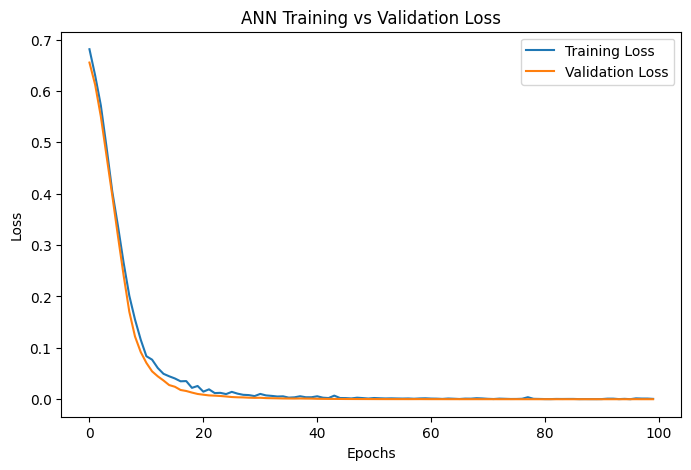

In [27]:
plt.figure(figsize=(8,5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("ANN Training vs Validation Loss")
plt.legend()
plt.show()

#make prediction

In [28]:
y_probability = model.predict(X_test)

y_pred = (y_probability >= 0.5).astype(int).ravel()

print(y_pred[:20])

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
[0 1 1 1 0 1 1 1 0 0 1 1 1 0 0 0 1 0 1 1]


#classification report

In [29]:
print(classification_report(
    y_test,
    y_pred,
    target_names=["Real Banknote", "Fake Banknote"]
))

               precision    recall  f1-score   support

Real Banknote       1.00      1.00      1.00       122
Fake Banknote       1.00      1.00      1.00        98

     accuracy                           1.00       220
    macro avg       1.00      1.00      1.00       220
 weighted avg       1.00      1.00      1.00       220



#confusion matrix

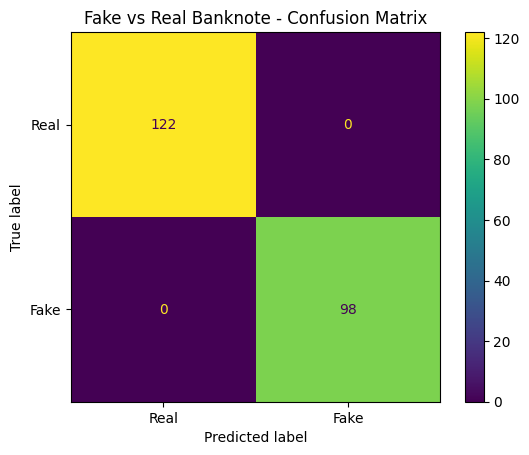

In [30]:
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Real", "Fake"]
)

disp.plot()
plt.title("Fake vs Real Banknote - Confusion Matrix")
plt.show()

#predict new banknote

In [31]:
VWTI = 2.2634
SWTI = -4.4862
CWTI = 3.6558
EI   = -0.612510

In [32]:
new_banknote = np.array([
    [2.2634, -4.4862, 3.6558, -0.612510]
])

new_banknote_scaled = scaler.transform(new_banknote)

prediction_probability = model.predict(new_banknote_scaled)[0][0]

if prediction_probability >= 0.5:
    print("Prediction: FAKE BANKNOTE")
else:
    print("Prediction: REAL BANKNOTE")

print("Fake probability:", prediction_probability)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step
Prediction: REAL BANKNOTE
Fake probability: 7.416434e-06


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


#save train model

In [33]:
model.save("fake_real_banknote_ann.keras")

In [34]:
import joblib

joblib.dump(scaler, "banknote_scaler.pkl")

['banknote_scaler.pkl']